In [2]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from scipy import signal

In [2]:
%pip install xrft 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# Demonstrator 2 - Diffusive and dispersive advection schemes on eddies

## Aim of Tutorial

Here we choose to demonstrate how the diffusive and dispersive properties of the advection scheme impact the outcome of a simulation in the case of the formation of eddies.

To run this demonstrator you must have compiled the CANAL test case via the command :

``` ./makenemo -a CANAL```

## Running the simulation
This simulation will represent the eddies formed when noise on the velocity is added at the junction betweem two currents going at the same velocity in opposite directions along the x-axis.

To run this simulation, we need change set ```nn_initcase``` to ```2``` and ```ln_sshnoise``` to ```.true.``` in the ```namusr_def``` section of the namelist.

__To make the recquired changes you can either modify the files yourself by following or you can execute the cell below__

In [14]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_shear_cen2_all_grid.nc
rm CANAL_shear_cen4_all_grid.nc

chmod -R a+x /"$DIR"/demo2_cfg/

bash /"$DIR"/demo2_cfg/shear_cfg.sh "$DIR"

bash /"$DIR"/demo2_cfg/cen_cfg.sh "$DIR"


rm: impossible de supprimer 'CANAL_shear_cen2_all_grid.nc': No such file or directory
rm: impossible de supprimer 'CANAL_shear_cen4_all_grid.nc': No such file or directory
+ set -v
set -u #Turn on error if usinf unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'


sed -i.bak \
-e 's/rn_domszx.*=.*\!/rn_domszx      =      	2000.    !/' \
-e 's/rn_domszy.*=.*\!/rn_domszy      =       1000.   !/' \
-e 's/rn_domszz.*=.*\!/rn_domszz      =       1000.  !/' \
-e 's/rn_dx.*=.*\!/rn_dx      =       10.     !/' \
-e 's/rn_dy.*=.*\!/rn_dy      =      

57c57
<    cn_exp =	'CANAL_shear_cen2'               		 !  experience name
---
>    cn_exp    =       'CANAL_shear'               		 !  experience name
167,168c167,168
<       nn_cen_h	=	2		!  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v  =       2		!  =2/4, vertical   2nd order CEN / 4th order COMPACT
---
>       nn_cen_h	=	4	!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v	=	4	!  =2/4, vertical   2nd order CEN / 4th order COMPACT


+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	0m53.392s
user	2m50.850s
sys	0m10.546s



Everything looks good



+ echo Run CANAL_shear_cen2_all_grid.nc completed
+ SED_EXPR=(-e 's/nn_cen_h.*=.*\!/nn_cen_h	=	4	!/' -e 's/nn_cen_v.*=.*\!/nn_cen_v	=	4	!/' -e "s/cn_exp.*=.*'.*'/cn_exp =	'CANAL_shear_cen4'/")
+ sed -i.bak -e 's/nn_cen_h.*=.*\!/nn_cen_h	=	4	!/' -e 's/nn_cen_v.*=.*\!/nn_cen_v	=	4	!/' -e 's/cn_exp.*=.*'\''.*'\''/cn_exp =	'\''CANAL_shear_cen4'\''/' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg


...

+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg.bak


57c57
<    cn_exp =	'CANAL_shear_cen4'               		 !  experience name
---
>    cn_exp =	'CANAL_shear_cen2'               		 !  experience name
167,168c167,168
<       nn_cen_h	=	4	!  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v	=	4	!  =2/4, vertical   2nd order CEN / 4th order COMPACT
---
>       nn_cen_h	=	2		!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v  =       2		!  =2/4, vertical   2nd order CEN / 4th order COMPACT


+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	0m52.260s
user	2m51.501s
sys	0m11.430s



Everything looks good

Run CANAL_shear_cen4_all_grid.nc completed


+ echo Run CANAL_shear_cen4_all_grid.nc completed


In [15]:
%%bash

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00


rm CANAL_shear_ubs_all_grid.nc
bash /"$DIR"/demo2_cfg/ubs_cfg.sh "$DIR"

+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ sed -i.bak -e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .true.  !/' -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' -e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' -e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' -e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' -e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' -e 's/nn_ubs_v.*=.*\!/nn_ubs_v  =       2               !/' -e 's/cn_exp.*=.*'\''.*'\''/cn_exp =  '\''CANAL_shear_ubs'\''/' -e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .true. !/' -e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .false. !/' -e 's/ln_traldf_blp.*=.*\!/ln_tral

57c57
<    cn_exp =  'CANAL_shear_ubs'               		 !  experience name
---
>    cn_exp =	'CANAL_shear_cen4'               		 !  experience name
165,166c165,166
<    ln_traadv_OFF        =       .false. !  No tracer advection
<    ln_traadv_cen        =       .false. !  2nd order centered scheme
---
>    ln_traadv_OFF	=	.false.	!  No tracer advection
>    ln_traadv_cen	=	.true.	!  2nd order centered scheme
169c169
<    ln_traadv_fct        =       .false. !  FCT scheme
---
>    ln_traadv_fct	=	.false.	!  FCT scheme
172c172
<    ln_traadv_mus        =       .false. !  MUSCL scheme
---
>    ln_traadv_mus	=	.false.	!  MUSCL scheme
174c174
<    ln_traadv_ubs        =       .true.  !  UBS scheme
---
>    ln_traadv_ubs	=	.false.	!  UBS scheme
176c176
<    ln_traadv_qck        =       .false. !  QUICKEST scheme
---
>    ln_traadv_qck	=	.false.	!  QUICKEST scheme


+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	0m59.554s
user	2m50.627s
sys	0m13.000s



Everything looks good



+ echo Run CANAL_shear_ubs_all_grid.nc completed


Run CANAL_shear_ubs_all_grid.nc completed


In [16]:
%%bash

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

rm CANAL_shear_fct2_all_grid.nc
rm CANAL_shear_fct4_all_grid.nc

bash /"$DIR"/demo2_cfg/fct_cfg.sh "$DIR"

rm: impossible de supprimer 'CANAL_shear_fct4_all_grid.nc': No such file or directory
+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ SED_EXPR=(-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .true.  !/' -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' -e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' -e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' -e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' -e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' -e 's/nn_fct_h.*=.*\!/nn_fct_h  =       2               !/' -e 's/nn_fct_v.*=.*\!/nn_fct_v  =       2               !/' -e "s/cn_exp.*=.*'.*'/cn_exp =  'CANAL_shear_fct2'/" -e 's/ln_traldf_OFF.*=.*\!/ln_trald

57c57
<    cn_exp =  'CANAL_shear_fct2'               		 !  experience name
---
>    cn_exp =  'CANAL_shear_ubs'               		 !  experience name
169,171c169,171
<    ln_traadv_fct        =       .true.  !  FCT scheme
<       nn_fct_h  =       2               !  =2/4, horizontal 2nd / 4th order
<       nn_fct_v  =       2               !  =2/4, vertical   2nd / COMPACT 4th order
---
>    ln_traadv_fct        =       .false. !  FCT scheme
>       nn_fct_h  =       4               !  =2/4, horizontal 2nd / 4th order
>       nn_fct_v  =       4               !  =2/4, vertical   2nd / COMPACT 4th order
174c174
<    ln_traadv_ubs        =       .false. !  UBS scheme
---
>    ln_traadv_ubs        =       .true.  !  UBS scheme


+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	1m4.421s
user	2m56.580s
sys	0m18.639s



Everything looks good



+ echo Run CANAL_shear_fct2_all_grid.nc completed
+ SED_EXPR=(-e 's/nn_fct_h.*=.*\!/nn_fct_h	=	4	!/' -e 's/nn_fct_v.*=.*\!/nn_fct_v	=	4	!/' -e "s/cn_exp.*=.*'.*'/cn_exp =	'CANAL_shear_fct4'/")
+ sed -i.bak -e 's/nn_fct_h.*=.*\!/nn_fct_h	=	4	!/' -e 's/nn_fct_v.*=.*\!/nn_fct_v	=	4	!/' -e 's/cn_exp.*=.*'\''.*'\''/cn_exp =	'\''CANAL_shear_fct4'\''/' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg


...

+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg.bak


57c57
<    cn_exp =	'CANAL_shear_fct4'               		 !  experience name
---
>    cn_exp =  'CANAL_shear_fct2'               		 !  experience name
170,171c170,171
<       nn_fct_h	=	4	!  =2/4, horizontal 2nd / 4th order
<       nn_fct_v	=	4	!  =2/4, vertical   2nd / COMPACT 4th order
---
>       nn_fct_h  =       2               !  =2/4, horizontal 2nd / 4th order
>       nn_fct_v  =       2               !  =2/4, vertical   2nd / COMPACT 4th order


+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	1m5.252s
user	3m0.644s
sys	0m19.722s



Everything looks good

Run CANAL_shear_fct4_all_grid.nc compleyed


+ echo Run CANAL_shear_fct4_all_grid.nc compleyed


In [4]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''

## CEN2 (dispersive)

In [5]:
#Open the simulation using the xr library

cen2 = xr.open_dataset(rep+'CANAL_shear_cen2_all_grid.nc')
cen4 = xr.open_dataset(rep+'CANAL_shear_cen4_all_grid.nc')
ubs = xr.open_dataset(rep+'CANAL_shear_ubs_all_grid.nc')
fct2 = xr.open_dataset(rep+'CANAL_shear_fct2_all_grid.nc')
fct4 = xr.open_dataset(rep+'CANAL_shear_fct4_all_grid.nc')

In [8]:
def show_t (t_list, param, title, file, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"
    im_list = []
    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(20, 5))
    for i, t in enumerate(t_list) : 
        # We select and show the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', interpolation = 'nearest', vmin=29, vmax=31)
        im_list.append(data)
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])
    plt.show()
    dataset.close()
    return im_list
    

In [9]:
t_list = [0, 10, 19]

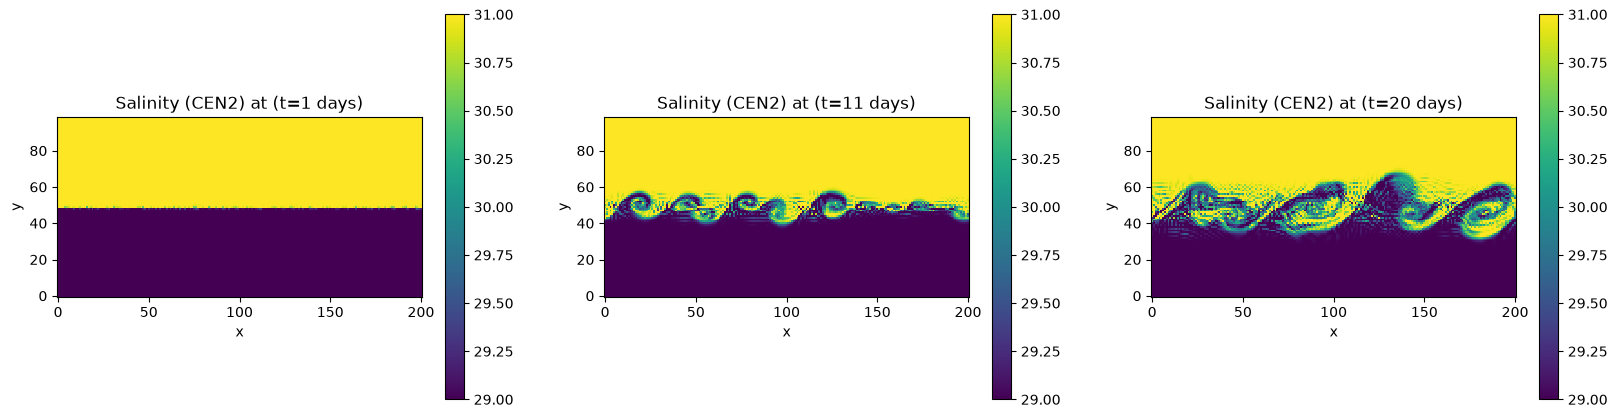

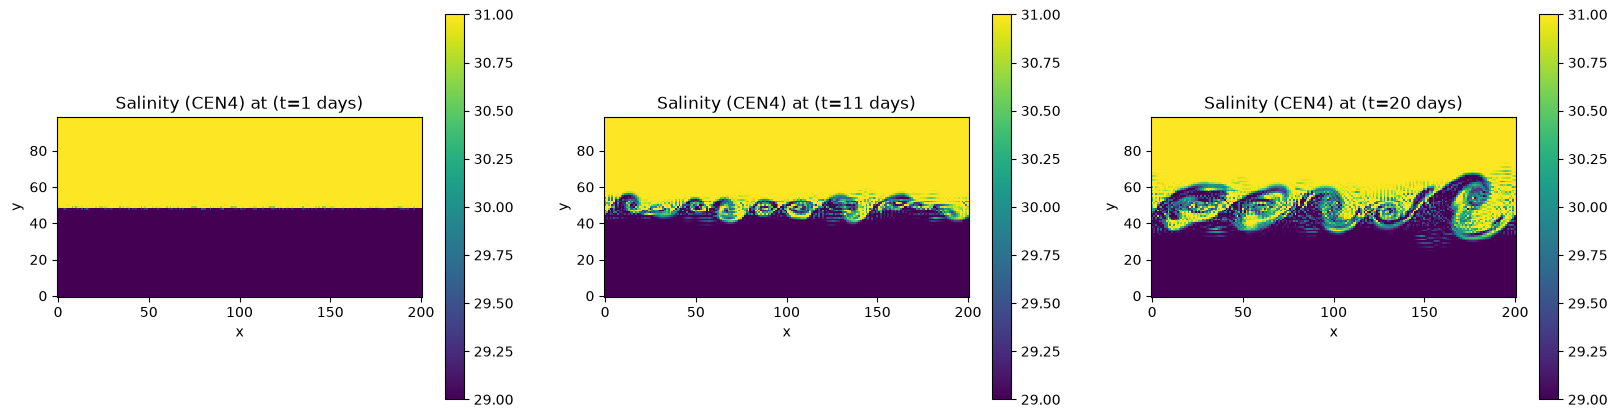

In [10]:
shear_cen2 = show_t(t_list, 'soce', 'Salinity (CEN2)', 'CANAL_shear_cen2_all_grid.nc', rep=rep)
shear_cen4 = show_t(t_list, 'soce', 'Salinity (CEN4)', 'CANAL_shear_cen4_all_grid.nc', rep=rep)

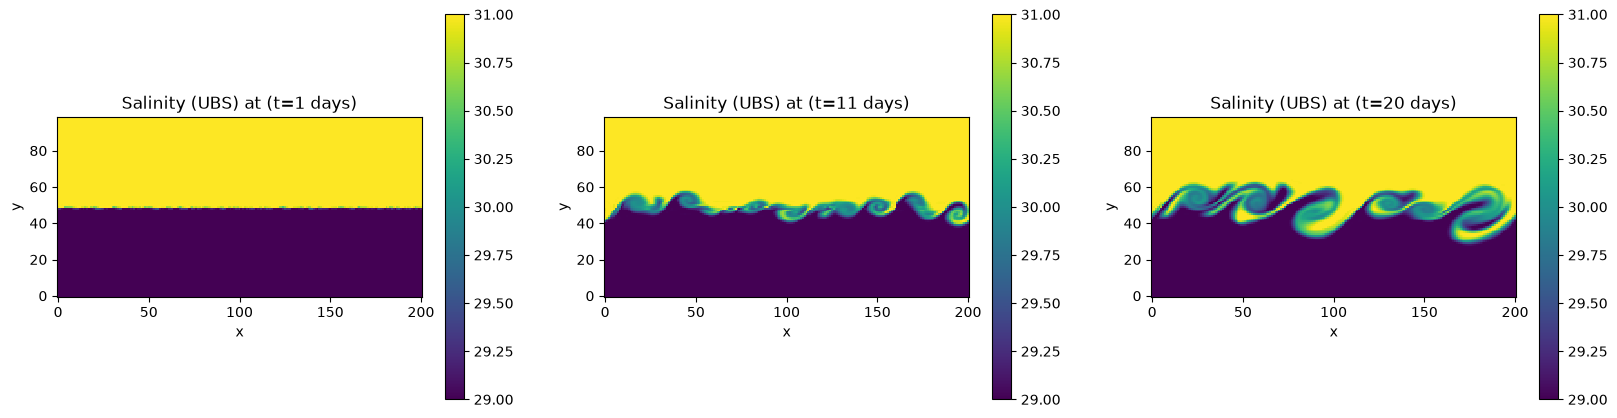

In [11]:
shear_ubs=show_t(t_list, 'soce', 'Salinity (UBS)', 'CANAL_shear_ubs_all_grid.nc', rep=rep)

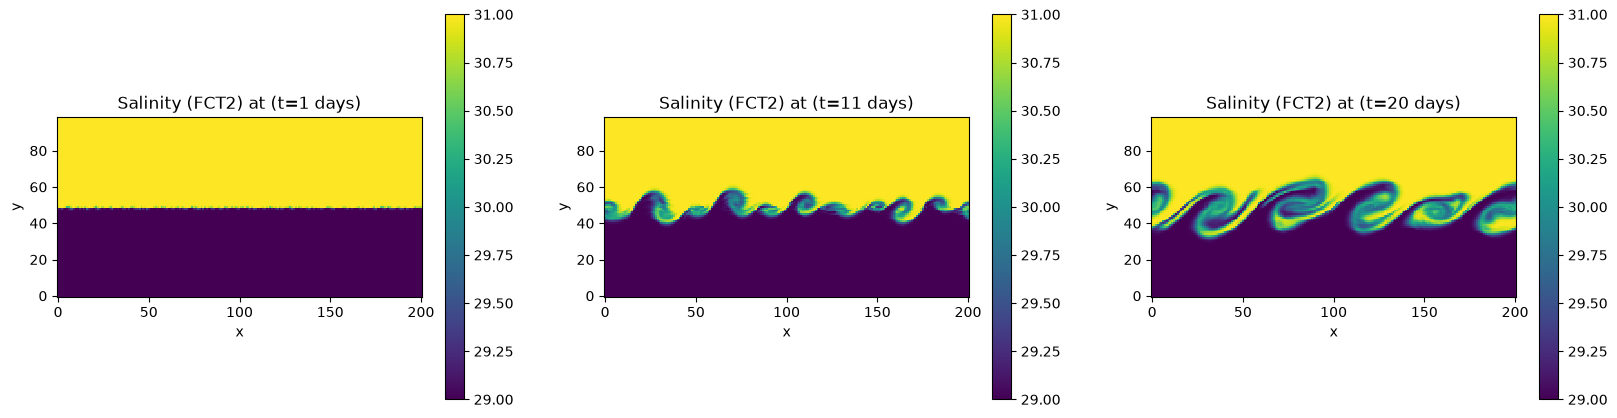

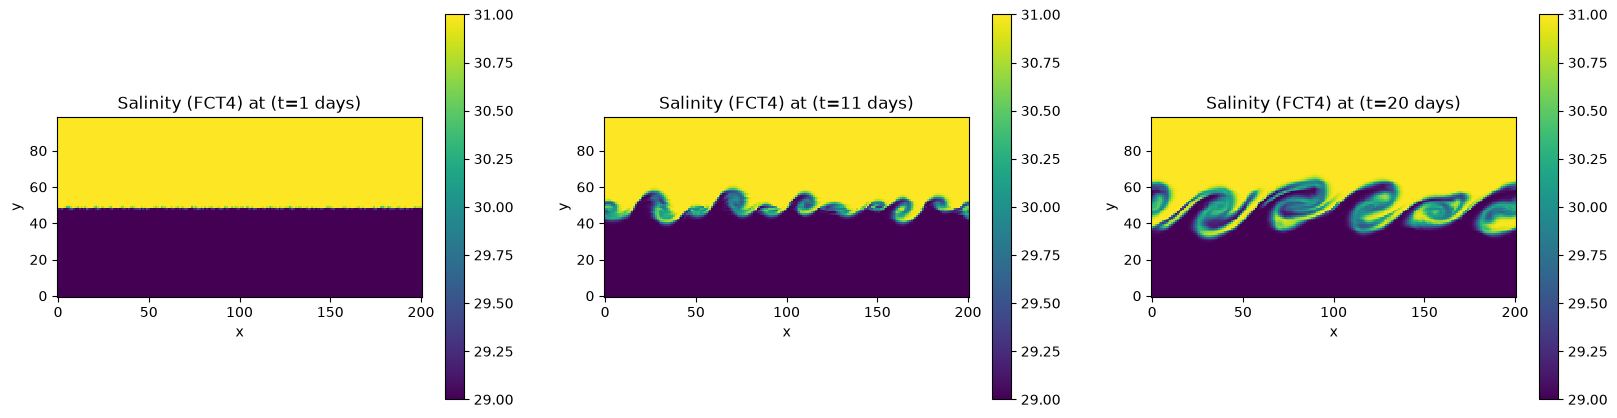

In [12]:
shear_fct2=show_t(t_list, 'soce', 'Salinity (FCT2)', 'CANAL_shear_fct2_all_grid.nc', rep=rep)
shear_fct4=show_t(t_list, 'soce', 'Salinity (FCT4)', 'CANAL_shear_fct2_all_grid.nc', rep=rep)

Text(0, 0.5, 'y')

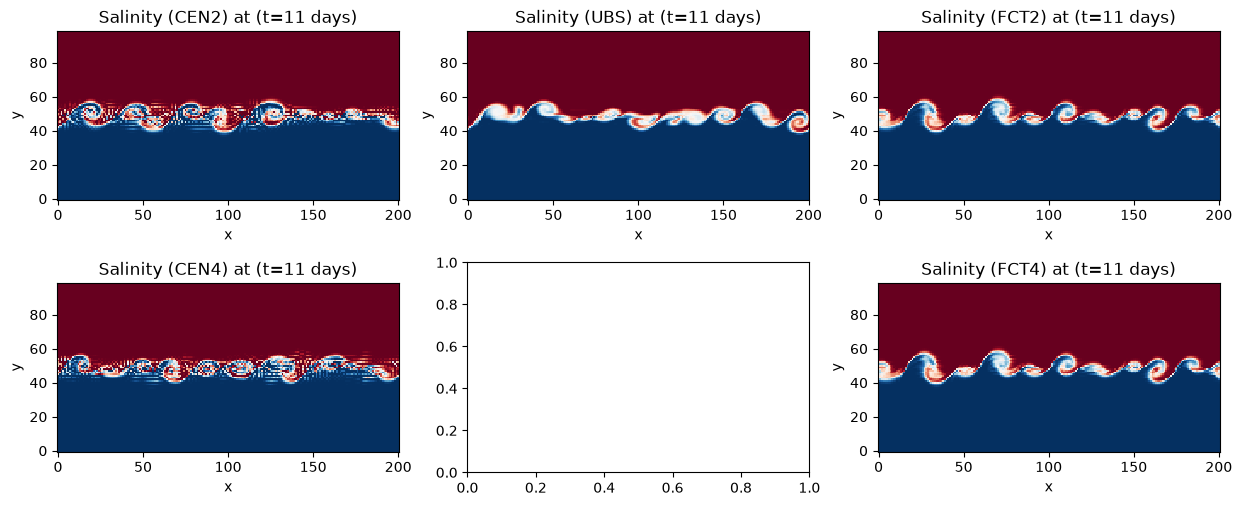

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(15,6))

axes[0][0].imshow(shear_cen2[1], origin='lower', interpolation='nearest', cmap = 'RdBu_r', vmin=29, vmax=31) 
axes[0][1].imshow(shear_ubs[1], origin='lower', interpolation='nearest',  cmap = 'RdBu_r', vmin=29, vmax=31) 
axes[0][2].imshow(shear_fct2[1], origin='lower', interpolation='nearest', cmap = 'RdBu_r', vmin=29, vmax=31) 
axes[1][0].imshow(shear_cen4[1], origin='lower', interpolation='nearest', cmap = 'RdBu_r', vmin=29, vmax=31) 
axes[1][2].imshow(shear_fct4[1], origin='lower', interpolation='nearest', cmap = 'RdBu_r', vmin=29, vmax=31) 

axes[0][0].set_title(f'Salinity (CEN2) at (t=11 days)')
axes[0][0].set_xlabel('x')
axes[0][0].set_ylabel('y')
axes[1][0].set_title(f'Salinity (CEN4) at (t=11 days)')
axes[1][0].set_xlabel('x')
axes[1][0].set_ylabel('y')
axes[0][1].set_title(f'Salinity (UBS) at (t=11 days)')
axes[0][1].set_xlabel('x')
axes[0][1].set_ylabel('y')
axes[0][2].set_title(f'Salinity (FCT2) at (t=11 days)')
axes[0][2].set_xlabel('x')
axes[0][2].set_ylabel('y')
axes[1][2].set_title(f'Salinity (FCT4) at (t=11 days)')
axes[1][2].set_xlabel('x')
axes[1][2].set_ylabel('y')

## FCT Gradient

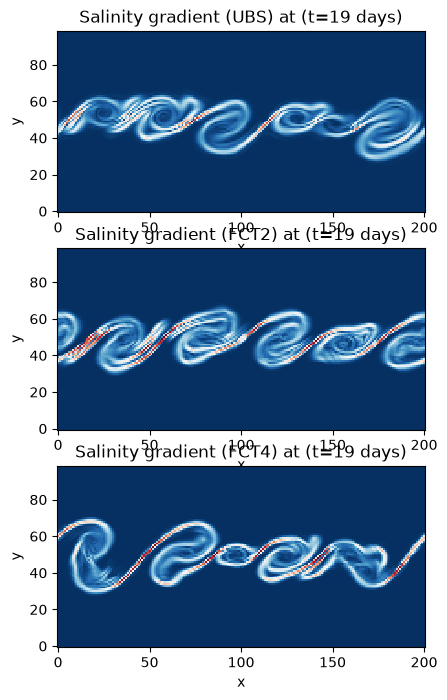

In [15]:

fig, axes = plt.subplots(3, 1, figsize=(12, 8))

# We select and show the desired field at different timesteps and at sea surface, excluding the walls
data = ubs['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[0].imshow(data, interpolation='nearest', origin='lower', cmap = 'RdBu_r')

axes[0].set_title(f'Salinity gradient (UBS) at (t=19 days)')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

data = fct2['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[1].imshow(data, interpolation='nearest', origin='lower', cmap = 'RdBu_r')

axes[1].set_title(f'Salinity gradient (FCT2) at (t=19 days)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')

data = fct4['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[2].imshow(data, interpolation='nearest', origin='lower', cmap = 'RdBu_r')

axes[2].set_title(f'Salinity gradient (FCT4) at (t=19 days)')
axes[2].set_xlabel('x')
axes[2].set_ylabel('y')
plt.show()

In [ ]:
schemes = {'cen2': cen2, 'cen4': cen4, 'fct2' : fct2, 'fct4' : fct4,  'ubs': ubs}
colors = {'cen2': 'red', 'cen4': 'orange',  'fct2' : 'green', 'fct4' : 'lightgreen', 'ubs': 'blue'}


## Tracer variance

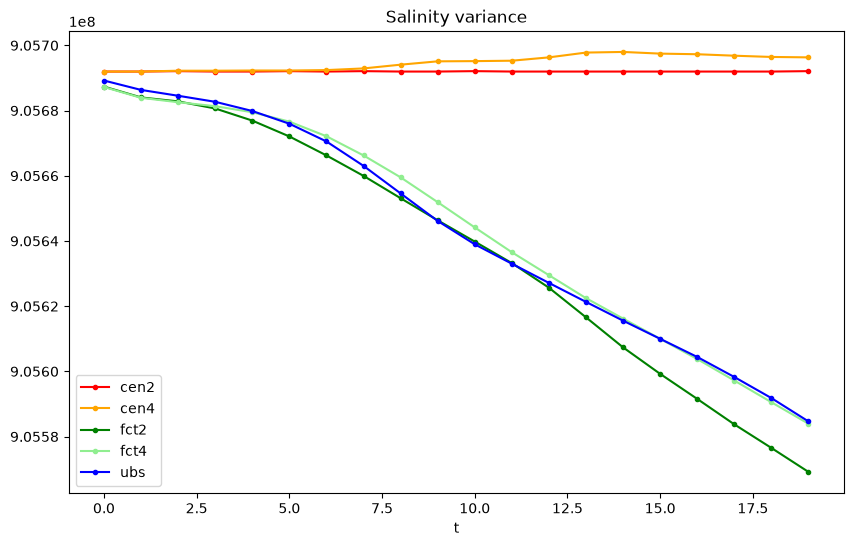

In [18]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))

for n, ds in schemes.items():
    s2c = ds['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
    dep = np.arange(s2c.shape[0])
    axes_salt2c.plot(dep,  s2c, '.-', color=colors[n], label = n)
    
axes_salt2c.legend()
axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()


## Gradient magnitude distribution

Text(0, 0.5, 'Frequency')

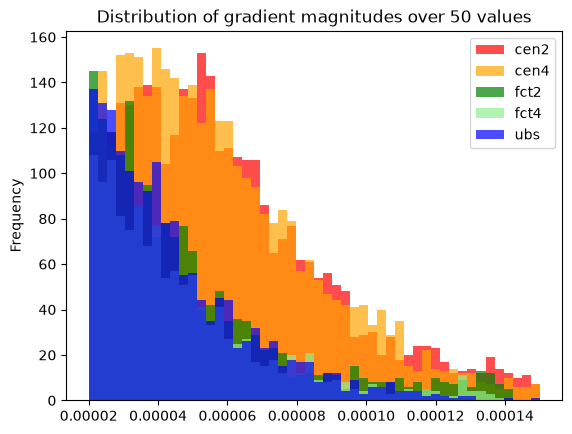

In [26]:
t = 15

for n, ds in schemes.items():
    ds_grad = ds.sssgrad.isel(time_counter = t)[40:60]
    ds_grad = np.array(ds_grad)
    ds_grad_0 = ds_grad[ds_grad != 0]
    plt.hist(ds_grad_0, bins=50, range=(0.00002, 0.00015), color=colors[n],alpha=0.7, label = n)

plt.legend()

plt.title("Distribution of gradient magnitudes over 50 values")

plt.ylabel("Frequency")

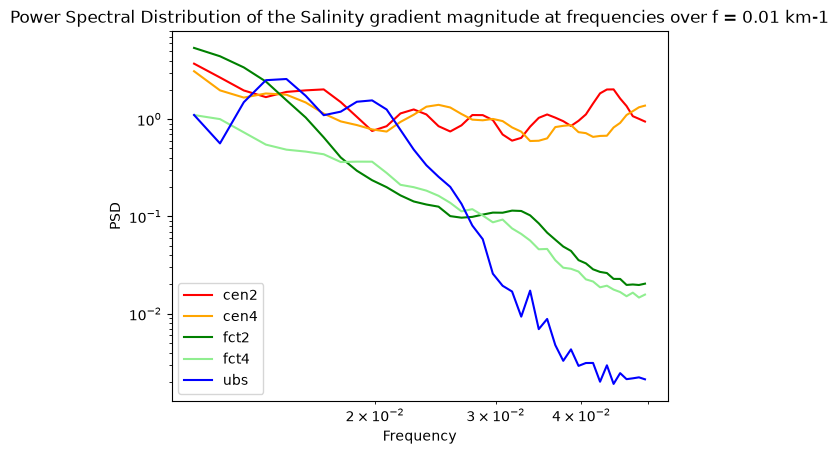

In [30]:
Fs = 1/10

for n, ds in schemes.items():
    fft=[[],[]]
    for i in range(20):
        dataset = ds.soce.isel(time_counter = -1, x_grid_T = 40 + i)
        soce = np.array(dataset)
        f, psd = signal.welch(soce, Fs, nperseg = 101, window = 'tukey')
        fft[0].append(f)
        fft[1].append(psd)
    psd_all = np.array(fft[1])      # shape (100, n_freq)
    mask = f > 0.01
    f = f[mask]
    moyennes = np.nanmean(psd_all, axis=tuple(range(psd_all.ndim - 1)))[mask] 
    
    plt.loglog(f, moyennes, color=colors[n], label = n)

#plt.loglog(f[5:20] , [k**(-5/3)/500 for k in f[5:20]], label = 'k^-5/3')
#plt.loglog(f[15:], [k**(-3)/300000 for k in f[15:]], label = 'k^-3')
plt.xlabel('Frequency')
plt.ylabel('PSD')
plt.title('Power Spectral Distribution of the Salinity gradient magnitude at frequencies over f = 0.01 km-1')
plt.legend()

In [ ]:
cen2.close()
ubs.close()
fct2.close()